# DSK807: Applied Machine Learning
## **L10 Hands-on: Neural Networks with Keras**

### Learning goals
By the end of this hands-on, you should be able to:

- prepare data for a neural network;
- identify the **input, hidden, and output layers**;
- use **ReLU** and **Sigmoid** activation functions;
- understand the role of the **loss function**, **optimizer**, **learning rate**, and **epochs**;
- build and evaluate a simple neural network in **Keras**;

We will use the **Breast Cancer Wisconsin** dataset from scikit-learn as a binary classification task.

## 1. Load the dataset

The dataset contains **30 numerical input features** and a **binary target**.

This means our network will have:
- **30 input features**
- one or more **hidden layers**
- **1 output neuron** for binary classification

In [2]:
import sys
print(sys.executable)
print(sys.version)

/Users/fangsiyu/dev-env/bin/python
3.13.11 (main, Dec  5 2025, 16:06:33) [Clang 17.0.0 (clang-1700.6.3.2)]


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

data = load_breast_cancer(as_frame=True)

df = data.frame.copy()

features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean smoothness",
    "mean concavity"
]

X = df[features]
y = df["target"]

print("X shape:", X.shape)
print("Classes:", data.target_names)
X.head()

X shape: (569, 5)
Classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean smoothness,mean concavity
0,17.99,10.38,122.80,0.11840,0.3001
1,20.57,17.77,132.90,0.08474,0.0869
2,19.69,21.25,130.00,0.10960,0.1974
3,11.42,20.38,77.58,0.14250,0.2414
4,20.29,14.34,135.10,0.10030,0.1980


### Question
1. How many neurons should the **input** of our network receive?
2. How many neurons should the **output layer** contain?
3. Which activation function should we use in the output layer?

For binary classification, our rule of thumb is:

**1 output neuron → Sigmoid → Binary Cross-Entropy**

## 2. Train/test split and feature scaling

Neural networks are sensitive to the scale of the input features.  
We therefore standardize the features before training.

**Important:** fit the scaler only on the training data.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train_scaled.shape)
print("Test samples:", X_test_scaled.shape)

Training samples: (455, 5)
Test samples: (114, 5)


## 3. Build a simple neural network

We will start with:

**30 inputs → Dense(16, ReLU) → Dense(8, ReLU) → Dense(1, Sigmoid)**

For one neuron:

$$
z = w_1x_1 + w_2x_2 + \cdots + w_nx_n + b
$$

$$
a = f(z)
$$

A **Dense** layer applies this operation to several neurons.

In [5]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)

model = keras.Sequential([
    keras.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241 (964.00 B)

 Trainable params: 241 (964.00 B)

 Non-trainable params: 0 (0.00 B)

### Inspect the architecture

Look at `model.summary()` and answer:

- How many trainable parameters does the first hidden layer have?
- Why does it have more parameters than `30 × 16`?
- What is the output shape of the final layer?

Recall that each neuron also has a **bias**:

$$
\text{parameters} = (\text{inputs} \times \text{neurons}) + \text{neurons}
$$

## 4. Compile the model

Building the architecture is not enough. We must tell Keras **how the network should learn**.

For this binary classification problem:

- **Loss:** Binary Cross-Entropy
- **Optimizer:** Adam
- **Learning rate:** 0.001
- **Metric:** Accuracy

The loss measures the error.  
The optimizer uses this error to update the network's weights.

In [6]:
optimizer = keras.optimizers.Adam(learning_rate=0.001)

model.compile(
    optimizer=optimizer,
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

## 5. Train the network

An **epoch** is one complete pass through the training dataset.

We will train for 30 epochs. We also reserve 20% of the training data for validation so that we can observe how the model behaves on unseen data during training.

In [7]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.20,
    verbose=1
)

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8049 - loss: 0.5813 - val_accuracy: 0.8352 - val_loss: 0.5691
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8544 - loss: 0.5432 - val_accuracy: 0.8462 - val_loss: 0.5325
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8736 - loss: 0.5090 - val_accuracy: 0.8462 - val_loss: 0.4988
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8874 - loss: 0.4778 - val_accuracy: 0.8681 - val_loss: 0.4671
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8874 - loss: 0.4489 - val_accuracy: 0.8901 - val_loss: 0.4375
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9011 - loss: 0.4221 - val_accuracy: 0.8791 - val_loss: 0.4095
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9066 - loss: 0.3969 - val_accuracy: 0.9011 - val_loss: 0.3826
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9093 - loss: 0.3727 - val_accuracy: 0.9231 - val_loss:

## 6. Visualize the learning process

During training we can inspect the **loss** and **accuracy** after every epoch.

Ideally:
- training loss decreases;
- validation loss also decreases;
- training and validation performance remain reasonably close.

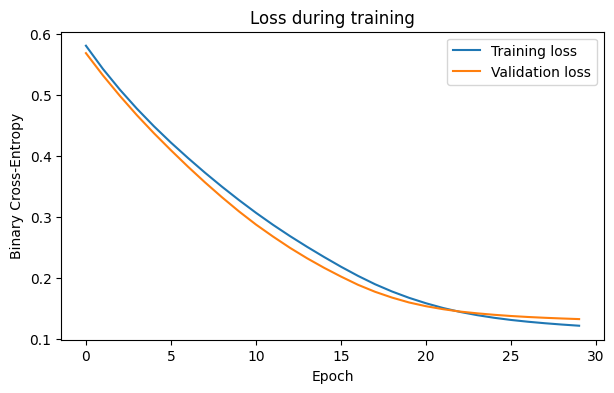

In [8]:
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(7, 4))
plt.plot(history_df["loss"], label="Training loss")
plt.plot(history_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.title("Loss during training")
plt.legend()
plt.show()

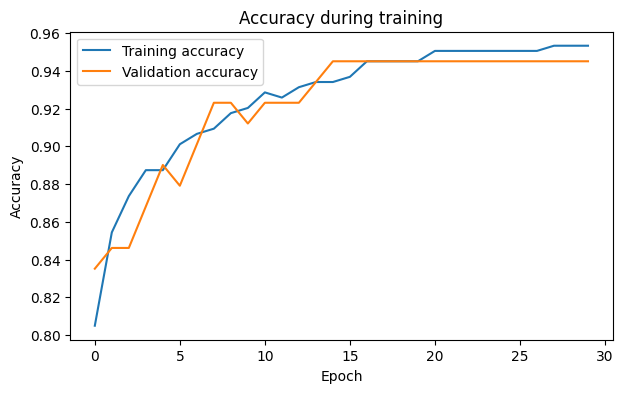

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(history_df["accuracy"], label="Training accuracy")
plt.plot(history_df["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy during training")
plt.legend()
plt.show()

### Discussion

Look at the two plots.

1. Is the model learning?
2. At approximately which epoch does the validation loss stop improving?
3. Do you see evidence of overfitting?
4. Would training for more epochs necessarily produce a better model?

## 7. Prediction: what does Sigmoid give us?

The final neuron uses **Sigmoid**, so the network outputs a value between 0 and 1.

This value can be interpreted as the model's estimated probability for class `1`.

We can then apply a threshold such as **0.5** to obtain a class prediction.

In [11]:
probabilities = model.predict(X_test_scaled[:10], verbose=0).flatten()
predictions = (probabilities >= 0.5).astype(int)

results = pd.DataFrame({
    "Probability": np.round(probabilities, 3),
    "Predicted class": predictions,
    "True class": y_test.iloc[:10].to_numpy()
})

results

,Probability,Predicted class,True class
0,0.001,0,0
1,0.997,1,1
2,0.039,0,0
3,0.147,0,1
4,0.000,0,0
5,0.981,1,1
6,0.999,1,1
7,0.001,0,0
8,0.002,0,0
9,0.000,0,0


## 8. Evaluate the model on the test set

In [12]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled, y_test, verbose=0
)

y_probability = model.predict(X_test_scaled, verbose=0).flatten()
y_pred = (y_probability >= 0.5).astype(int)

print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=data.target_names))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Test loss:     0.1936
Test accuracy: 0.9123

              precision    recall  f1-score   support

   malignant       0.83      0.95      0.89        42
      benign       0.97      0.89      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114

Confusion matrix:
[[40  2]
 [ 8 64]]


---

## Exercise: Build a Neural Network for Wine Classification
Using the Wine dataset, build a neural network that predicts the wine class.
Students should:
1. Explore X and y and identify the number of input features and classes.
2. Split the dataset into training and test sets using stratification.
3. Standardize the features using StandardScaler.
4. Build a Keras neural network with two hidden layers.
5. Decide themselves:
   - number of input features,
   - number of output neurons,
   - hidden-layer activation,
   - output activation,
   - appropriate loss function.
6. Train the model for 30 epochs.
7. Plot training and validation loss and accuracy.
8. Evaluate the model on the test set.
9. Experiment with at least two architectures, e.g. 16 → 8 versus 32 → 16 → 8.
10. Change the learning rate and/or number of epochs and discuss what happens.

In [8]:
from sklearn.datasets import load_wine
import torch


wine = load_wine(as_frame=True)

X = wine.data
y = wine.target

print(X.shape)
print(y.value_counts())
X.head()

(178, 13)
target
1    71
0    59
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

print(X_train.shape, X_test.shape)

(142, 13) (36, 13)


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = torch.tensor(scaler.fit_transform(X_train), dtype=torch.float32).to('mps')
X_test  = torch.tensor(scaler.transform(X_test),  dtype=torch.float32).to('mps')

y_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32).to('mps') # _train.to_numpy() 這步驟才能將 series 轉換
y_test  = torch.tensor(y_test.to_numpy(),  dtype=torch.float32).to('mps')

In [41]:
import torch.nn as nn

class WineNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(13, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3),
        )


    def forward(self, x):
        return self.net(x)

model = WineNet().to('mps')
loss_fn = nn.CrossEntropyLoss()


from torch.utils.data import TensorDataset, DataLoader

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

def evaluate(X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = loss_fn(logits, y).item()
        acc = (logits.argmax(dim=1) == y).float().mean().item()
    return loss, acc


history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

for epoch in range(100):
    model.train()
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()

    train_loss, train_acc = evaluate(X_train, y_train)
    test_loss, test_acc = evaluate(X_test, y_test)
    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)

    print(f"epoch {epoch+1:2d} | train loss {train_loss:.4f} acc {train_acc:.3f} "
          f"| val loss {test_loss:.4f} acc {test_acc:.3f}")

epoch  1 | train loss 1.0118 acc 0.782 | val loss 1.0019 acc 0.778
epoch  2 | train loss 0.8077 acc 0.944 | val loss 0.7841 acc 1.000
epoch  3 | train loss 0.5514 acc 0.979 | val loss 0.5170 acc 1.000
epoch  4 | train loss 0.3518 acc 0.993 | val loss 0.3280 acc 0.972
epoch  5 | train loss 0.2253 acc 0.993 | val loss 0.2227 acc 0.972
epoch  6 | train loss 0.1368 acc 1.000 | val loss 0.1549 acc 0.944
epoch  7 | train loss 0.0732 acc 1.000 | val loss 0.1044 acc 0.944
epoch  8 | train loss 0.0364 acc 1.000 | val loss 0.0725 acc 1.000
epoch  9 | train loss 0.0198 acc 1.000 | val loss 0.0530 acc 1.000
epoch 10 | train loss 0.0115 acc 1.000 | val loss 0.0480 acc 1.000
epoch 11 | train loss 0.0074 acc 1.000 | val loss 0.0539 acc 0.972
epoch 12 | train loss 0.0054 acc 1.000 | val loss 0.0625 acc 0.972
epoch 13 | train loss 0.0039 acc 1.000 | val loss 0.0566 acc 0.972
epoch 14 | train loss 0.0030 acc 1.000 | val loss 0.0510 acc 0.972
epoch 15 | train loss 0.0024 acc 1.000 | val loss 0.0513 acc 0

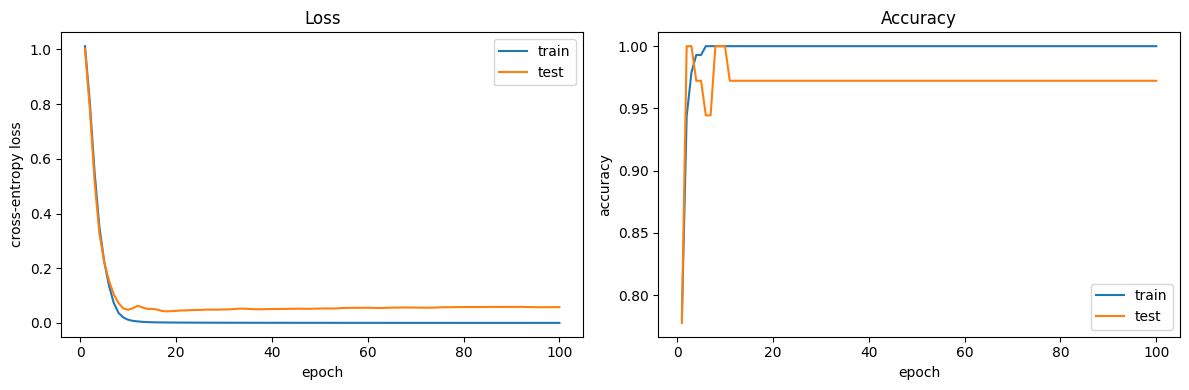

In [42]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs, history["train_loss"], label="train")
ax1.plot(epochs, history["test_loss"], label="test")
ax1.set_title("Loss")
ax1.set_xlabel("epoch")
ax1.set_ylabel("cross-entropy loss")
ax1.legend()

ax2.plot(epochs, history["train_acc"], label="train")
ax2.plot(epochs, history["test_acc"], label="test")
ax2.set_title("Accuracy")
ax2.set_xlabel("epoch")
ax2.set_ylabel("accuracy")
ax2.legend()

plt.tight_layout()
plt.show()

In [35]:
test_loss, test_acc = evaluate(X_test, y_test)
print(f"test loss {test_loss:.4f} | test acc {test_acc:.3f}")

test loss 0.0575 | test acc 0.972


In [37]:
from sklearn.metrics import confusion_matrix, classification_report

model.eval()
with torch.no_grad():
    y_pred = model(X_test).argmax(dim=1)

print(confusion_matrix(y_test.cpu(), y_pred.cpu()))
print(classification_report(y_test.cpu(), y_pred.cpu(), digits=3))

[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]
              precision    recall  f1-score   support

         0.0      1.000     1.000     1.000        12
         1.0      0.933     1.000     0.966        14
         2.0      1.000     0.900     0.947        10

    accuracy                          0.972        36
   macro avg      0.978     0.967     0.971        36
weighted avg      0.974     0.972     0.972        36



## 第 9 點：架構大小的差異

### 兩個架構差在哪

16 → 8 是兩層隱藏層，32 → 16 → 8 是三層，而且每層更寬。用前面算參數量的方法（每層 in × out + out）：

16 → 8：13×16+16 = 224，16×8+8 = 136，8×3+3 = 27，共 **387** 個參數。

32 → 16 → 8：13×32+32 = 448，32×16+16 = 528，16×8+8 = 136，8×3+3 = 27，共 **1,139** 個參數。

大的那個大約是小的三倍。參數越多，模型能表達的函數就越複雜，這叫做模型的**容量（capacity）**。

### 理論上會發生什麼

容量大是雙面刃。好處是能學更複雜的決策邊界；壞處是在資料少的時候，多出來的參數很容易被拿去「記住」訓練資料的細節和雜訊，也就是 overfitting。這裡的訓練集只有約 113 筆，而大模型有 1,139 個參數，參數比資料多了十倍，overfitting 的風險明顯比較高。

在 loss 圖上，overfitting 的樣子就是第 7 步講的：訓練 loss 繼續降，驗證 loss 在某個時間點停住或回升，兩條線拉開。所以你可以預期，**大模型的兩條線比較可能分開，而且分開得比較早**。

另一方面，大模型通常**訓練 loss 降得比較快**，因為有更多參數可以調整，同樣的 epoch 數內更容易把訓練資料擬合好。

### 但在 Wine 上，差異可能很小

Wine 是一個相對簡單的問題，三個類別在 13 個特徵構成的空間裡分得很開，連邏輯斯迴歸這種線性模型都能做得很好。也就是說，16 → 8 的容量已經綽綽有餘，加大模型不太會帶來準確率上的提升，最多是學得快一點、或 overfit 得明顯一點。

而且驗證集只有約 29 筆，錯一筆就差 3.4%。兩個架構的準確率如果只差一兩筆，很可能只是隨機性造成的（初始權重、shuffle 順序不同），不足以說哪個比較好。比較時要固定 `torch.manual_seed`，最好換幾個種子各跑一次，看差異是不是穩定存在。

## 第 10 點：學習率和 epoch 數

### 先算一下總共更新了幾次

這是理解這兩個參數的關鍵。前面說過，batch size 32、訓練集約 113 筆，每個 epoch 更新 4 次權重。30 個 epoch 總共只更新大約 **120 次**。權重最後走到哪裡，取決於「每一步跨多大」（學習率）乘上「總共走幾步」（epoch 數 × 每 epoch 更新次數）。

### 學習率

學習率通常以 10 倍為單位去試，例如 0.01、0.001、0.0001，因為它的影響是乘法性的，0.001 和 0.002 差異不大，0.001 和 0.01 才看得出明顯不同。

**學習率太大**（例如 0.1）：每一步跨太遠，容易越過 loss 的最低點，在兩側跳來跳去。在圖上會看到 loss 曲線抖動、不平滑，嚴重時 loss 不降反升。在 Wine 這種簡單問題上，Adam 配 0.01 很可能還是能正常收斂，而且比 0.001 快。

**學習率太小**（例如 0.0001）：每一步都很小，120 步可能根本走不到底。在圖上會看到兩條 loss 線都還在緩慢下降，到第 30 個 epoch 還沒有變平，準確率也還沒到頂，這叫 **underfitting**（還沒學完）。

### Epoch 數

**Epoch 太少**：跟學習率太小的效果類似，模型還沒學完就停了，曲線結尾還在往下走。

**Epoch 太多**：訓練 loss 會一直降，幾乎趨近 0；但驗證 loss 到某一點之後可能開始回升，因為模型開始記訓練資料。這時多跑的 epoch 不但沒幫助，還讓模型變差。

### 兩者會互相影響

學習率和 epoch 數要一起看。學習率調小 10 倍，通常需要更多 epoch 才能達到同樣的程度；學習率調大，可能幾個 epoch 就收斂，剩下的 epoch 就開始 overfit。

把第 9 點也加進來：大模型 + 大學習率 + 很多 epoch，是最容易 overfit 的組合；小模型 + 小學習率 + 少 epoch，則最容易 underfit。

## 比較時要注意的事

每次只改一個東西（例如固定架構只改學習率），其他全部維持不變，包括資料切分和隨機種子，否則看到差異也不知道是哪個改動造成的。判斷好壞時看**驗證集**的 loss 曲線，測試集照上一步說的，只留給最後選定的模型。

要做這些實驗，`WineNet` 需要改成可以傳入隱藏層大小，訓練迴圈也最好包成一個函數，方便換參數重跑。要繼續的話，下一步就來改這部分。